In [19]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
from sklearn.linear_model import RidgeCV

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
TRACK = "list_aware"                     # "off_market" or "list_aware", reads oof_preds/<TRACK>/
BASE_MODELS = None                        # list of MODEL_NAMEs to stack, or None for every file in oof_preds/<TRACK>/
ALPHAS = np.logspace(-4, 3, 50)           # ridge penalties to search over
META_TRAIN_MONTHS = 6                     # each month's meta model is fit on the base predictions of the META_TRAIN_MONTHS months before it

META_MODELS = {
    "ridge": lambda: RidgeCV(alphas=ALPHAS),
}

In [21]:
from training_utils import OOF_DIR, VALIDATION_MONTHS

paths = sorted((OOF_DIR / TRACK).glob("*.parquet"))
if BASE_MODELS is not None:
    paths = [path for path in paths if path.stem in BASE_MODELS]
if not paths:
    raise FileNotFoundError(f"No out-of-fold predictions in {OOF_DIR / TRACK}. Run the training notebooks first.")

oof = {path.stem: pd.read_parquet(path).set_index("ml_num") for path in paths}
for name, preds in oof.items():
    print(f"{name:<20} {len(preds):>7,} homes  {preds['month'].min()} to {preds['month'].max()}")

# One column of log price predictions per base model, keeping only homes every model predicted.
X = pd.concat({name: np.log(preds["predicted_price"]) for name, preds in oof.items()}, axis=1, join="inner")
homes = next(iter(oof.values())).loc[X.index, ["month", "house_type_name", "sold_price"]].sort_values("month")
X = X.loc[homes.index]
y = np.log(homes["sold_price"])

val_months = [str(month) for month in VALIDATION_MONTHS]
is_val = homes["month"].isin(val_months)
print(f"\nbase models: {list(X.columns)}")
print(f"meta train: {(~is_val).sum():,} homes from {homes.loc[~is_val, 'month'].min()} to {homes.loc[~is_val, 'month'].max()}")
print(f"meta val:   {is_val.sum():,} homes from {val_months[0]} to {val_months[-1]}")

catboost              22,238 homes  2025-06 to 2026-05
lightgbm              22,238 homes  2025-06 to 2026-05
lightgbm_split_apartment  32,705 homes  2024-12 to 2026-05
xgboost               22,238 homes  2025-06 to 2026-05

base models: ['catboost', 'lightgbm', 'lightgbm_split_apartment', 'xgboost']
meta train: 12,169 homes from 2025-06 to 2025-11
meta val:   10,069 homes from 2025-12 to 2026-05


In [22]:
def mdape_log(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape_log(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))


def meta_walk_forward(make_meta, months=val_months, debug=True):
    """Each validation month is predicted by a meta model fit on the base predictions of
    the META_TRAIN_MONTHS months just before it, a rolling window.
    Returns the last month's meta model and the log price predictions of every month."""
    predictions = []
    for month in months:
        window_start = str(pd.Period(month, freq="M") - META_TRAIN_MONTHS)
        is_train = (homes["month"] >= window_start) & (homes["month"] < month)
        is_month = homes["month"] == month
        meta = make_meta().fit(X[is_train], y[is_train])
        pred = pd.Series(meta.predict(X[is_month]), index=X.index[is_month])
        predictions.append(pred)
        if debug:
            print(f"{month}: trained on {is_train.sum():,} homes, predicted {is_month.sum():,}  "
                  f"MdAPE {mdape_log(y[is_month], pred):.2f}%  MAPE {mape_log(y[is_month], pred):.2f}%", flush=True)
    predictions = pd.concat(predictions)
    if debug:
        y_pred = y.loc[predictions.index]
        print(f"total: predicted {len(predictions):,} homes  "
              f"MdAPE {mdape_log(y_pred, predictions):.2f}%  MAPE {mape_log(y_pred, predictions):.2f}%", flush=True)
    return meta, predictions

In [23]:
meta_models, meta_preds = {}, {}
for name, make_meta in META_MODELS.items():
    print(name)
    meta_models[name], meta_preds[name] = meta_walk_forward(make_meta)
    print()

ridge
2025-12: trained on 12,169 homes, predicted 1,238  MdAPE 3.71%  MAPE 4.73%
2026-01: trained on 11,124 homes, predicted 1,058  MdAPE 3.69%  MAPE 4.64%
2026-02: trained on 10,114 homes, predicted 1,442  MdAPE 3.93%  MAPE 5.09%
2026-03: trained on 9,890 homes, predicted 1,816  MdAPE 3.92%  MAPE 5.05%
2026-04: trained on 9,671 homes, predicted 2,224  MdAPE 4.00%  MAPE 4.98%
2026-05: trained on 9,645 homes, predicted 2,291  MdAPE 4.12%  MAPE 5.27%
total: predicted 10,069 homes  MdAPE 3.94%  MAPE 5.01%



In [24]:
# Every candidate scored on the same validation homes.
X_val, y_val = X[is_val], y[is_val]
candidates = {name: X_val[name] for name in X_val.columns}
candidates["simple average"] = X_val.mean(axis=1)
candidates["median"] = X_val.median(axis=1)
for name, pred in meta_preds.items():
    candidates[f"meta ({name})"] = pred.loc[X_val.index]

scores = pd.DataFrame({
    "MdAPE": {name: mdape_log(y_val, pred) for name, pred in candidates.items()},
    "MAPE": {name: mape_log(y_val, pred) for name, pred in candidates.items()},
}).round(2).sort_values("MdAPE")
scores

,MdAPE,MAPE
meta (ridge),3.94,5.01
simple average,3.94,5.02
median,3.95,5.03
xgboost,4.01,5.10
lightgbm_split_apartment,4.01,5.16
catboost,4.04,5.17
lightgbm,4.07,5.21


In [25]:
# Weights of each meta model trained for the last validation month.
weights = pd.DataFrame({name: pd.Series(meta.coef_, index=X.columns) for name, meta in meta_models.items()})
weights.loc["intercept"] = [meta.intercept_ for meta in meta_models.values()]
weights.loc["sum of weights"] = weights.drop(index="intercept").sum()
if "ridge" in meta_models:
    print(f"ridge alpha: {meta_models['ridge'].alpha_:.4g}")
weights.round(4)

ridge alpha: 0.3728


,ridge
catboost,0.0772
lightgbm,0.2024
lightgbm_split_apartment,0.2670
xgboost,0.4635
intercept,-0.1392
sum of weights,1.0101


Diagnostics for ridge


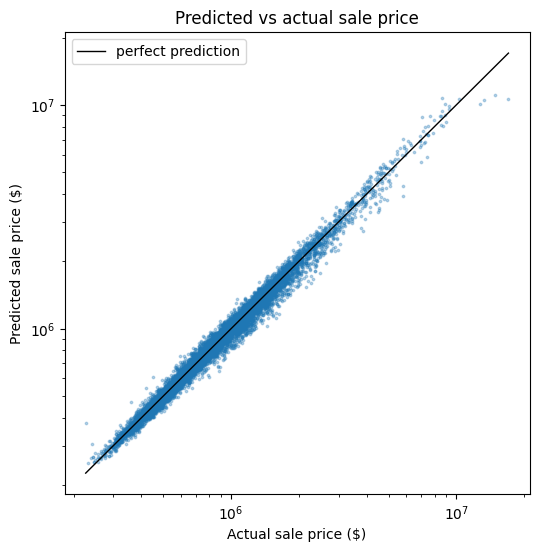

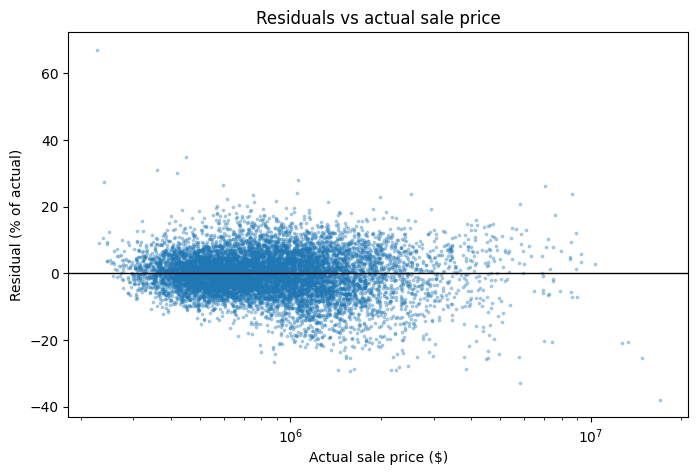

,month,house_type_name,sold_price,actual_price,predicted_price,error_pct
ml_num,,,,,,
SYN-0138680,2026-03,Condo Apt,226200.0,226200.0,378113.0,67.2
SYN-0090330,2026-05,Detached,17035700.0,17035700.0,10574507.0,-37.9
SYN-0093108,2026-04,Detached,450000.0,450000.0,606597.0,34.8
SYN-0072598,2026-02,Co-Op Apt,5816500.0,5816500.0,3902180.0,-32.9
SYN-0139619,2026-04,Co-Op Apt,358200.0,358200.0,468781.0,30.9
SYN-0083582,2026-03,Condo Apt,418100.0,418100.0,544449.0,30.2
SYN-0044938,2026-04,Semi-Detached,1575300.0,1575300.0,1112723.0,-29.4
SYN-0080839,2026-03,Semi-Detached,2254500.0,2254500.0,1598291.0,-29.1
SYN-0017920,2026-03,Detached,2161300.0,2161300.0,1532231.0,-29.1


In [26]:
import diagnostics

print("Diagnostics for ridge")
actual = homes.loc[X_val.index, "sold_price"]
predicted = np.round(np.exp(meta_preds["ridge"].loc[X_val.index]))

diagnostics.plot_predicted_vs_actual(actual, predicted)
diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.worst_predictions(homes.loc[X_val.index], actual, predicted)

In [27]:
# Residual by feature for the ridge meta model, the same view as the base-model notebooks.
# Each validation month's features are built only from earlier sales.
import matplotlib.pyplot as plt
import seaborn as sns

import data
from training_utils import walk_forward_folds
from xxbonkxx_features import list_aware_features, off_market_features


def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)


def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


make_features = off_market_features if TRACK == "off_market" else list_aware_features
listings = data.load("listings")
X_features = pd.concat(
    fold.X_homes
    for fold in walk_forward_folds(listings, make_features, TRACK, months=VALIDATION_MONTHS)
)
X_features = X_features.set_index(listings.loc[X_features.index, "ml_num"]).loc[actual.index]

print(f"Ridge residuals by feature ({len(X_features.columns)} features, {len(X_features):,} homes)")
plot_residuals_by_feature(X_features, actual, predicted)


KeyboardInterrupt: 